# Задание 3. Уравнения Бернулли в прикладных задачах

## Справка: уравнение Бернулли

**Уравнением Бернулли** называется ОДУ первого порядка вида

$$y' + p(t)\,y = q(t)\,y^{n}, \qquad n \neq 0,\,1,$$

где $p(t)$ и $q(t)$ — заданные функции. При $n=0$ и $n=1$ уравнение линейное, при остальных $n$ оно нелинейное, но сводится к линейному **заменой**

$$z = y^{1-n} \quad\Longrightarrow\quad z' + (1-n)\,p(t)\,z = (1-n)\,q(t).$$

---

## Задача 1. Катер с разряжающейся батареей

Катер массой $m$ движется по прямой со скоростью $v(t) > 0$, $v(0) = v_0$. Электромотор питается от батареи, которая по ходу движения разряжается.

**Исходные соотношения.**

- Сила сопротивления воды пропорциональна скорости.
- Мощность на винте убывает со временем по мере разряда батареи:
$$P(t) = P_0\,e^{-t/\tau},$$
где $P_0$ — начальная мощность, $\tau$ — характерное время разряда.
- Мощность равна силе, умноженной на скорость, $P = F_{\text{thrust}}\,v$, поэтому тяга
$$F_{\text{thrust}}(t, v) = \frac{P(t)}{v} = \frac{P_0\,e^{-t/\tau}}{v}.$$
- Используйте Второй закон Ньютона:
$$F = m\,\frac{dv}{dt}.$$

**Задание.**

1. Подставьте выражения для сил и получите ОДУ для $v(t)$.
2. Докажите, что это уравнение Бернулли: приведите его к каноническому виду и укажите $p(t)$, $q(t)$, $n$.
3. Решите исходное уравнение в SymPy (`dsolve`) и сверьте с ручным ответом.
4. Постройте графики $v(t)$ при разных $\tau$.

2.16024689946929*sqrt(1.21428571428571*exp(0.428571428571429*t) - 1.0)*exp(-0.714285714285714*t)


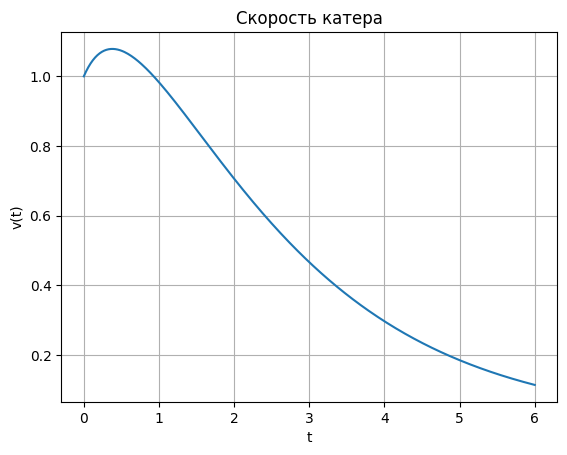

In [20]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

t = sp.symbols('t', positive=True)
v = sp.Function('v')

#как вы советывали сразу в числах потому что в символах страшная формула выходит
m_val, k_val, P0_val, tau_val, v0_val = 1.0, 0.5, 1.0, 0.7, 1.0

#я привел к каноническому виду на листочке еще на паре но листочек благополучно потерян если надо еще раз приведу
p = k_val / m_val
q = P0_val / m_val * sp.exp(-t / tau_val)
n = -1

ode = sp.Eq(v(t).diff(t) + p * v(t), q * v(t)**n)
sol = sp.dsolve(ode, v(t), ics={v(0): v0_val})
sol = sp.simplify(sol.rhs)
print(sol)

# график
f = sp.lambdify(t, sol, 'numpy')
t_vals = np.linspace(0, 6, 400)
plt.plot(t_vals, f(t_vals))
plt.xlabel('t'); plt.ylabel('v(t)'); plt.grid(True)
plt.title('Скорость катера')
plt.show()

1.0*sqrt(1.22222222222222*exp(9.0*t) - 0.222222222222222)*exp(-5.0*t)


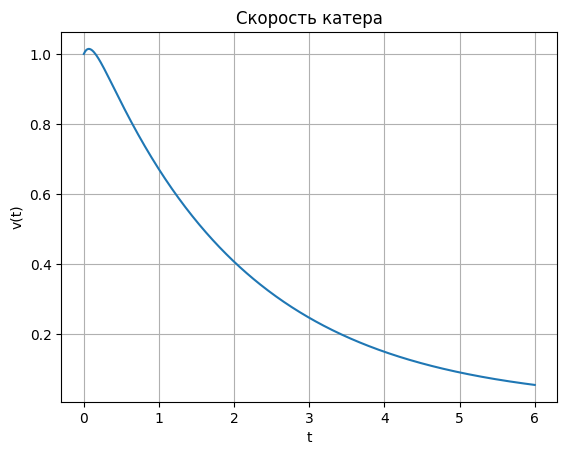

In [21]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

t = sp.symbols('t', positive=True)
v = sp.Function('v')

#как вы советывали сразу в числах потому что в символах страшная формула выходит
m_val, k_val, P0_val, tau_val, v0_val = 1.0, 0.5, 1.0, 0.1, 1.0

#я привел к каноническому виду на листочке еще на паре но листочек благополучно потерян если надо еще раз приведу
p = k_val / m_val
q = P0_val / m_val * sp.exp(-t / tau_val)
n = -1

ode = sp.Eq(v(t).diff(t) + p * v(t), q * v(t)**n)
sol = sp.dsolve(ode, v(t), ics={v(0): v0_val})
sol = sp.simplify(sol.rhs)
print(sol)

# график
f = sp.lambdify(t, sol, 'numpy')
t_vals = np.linspace(0, 6, 400)
plt.plot(t_vals, f(t_vals))
plt.xlabel('t'); plt.ylabel('v(t)'); plt.grid(True)
plt.title('Скорость катера')
plt.show()

## Задача 2. Популяция в линейно ухудшающейся среде

Рассмотрим динамику численности популяции $N(t)$ в условиях постепенного ухудшения среды (загрязнение водоёма, климатический сдвиг).

**Исходные соотношения.**

- **Удельная скорость роста** — прирост на одну особь:
$$\frac{N'}{N} = \frac{1}{N}\frac{dN}{dt}.$$
- Введём **замедляющий член** — коэффициент естественного прироста, линейно убывающий со временем:
$$r(t) = a - b\,t, \qquad a,\,b > 0.$$
- Внутривидовая конкуренция за ограниченные ресурсы: торможение на одну особь пропорционально численности, то есть вклад в $\dfrac{dN}{dt}$ равен $-c\,N^{2}$, $c>0$.

**Задание.**

1. Составьте ОДУ для $N(t)$ и запишите его в каноническом виде Бернулли.
2. Докажите, что это уравнение Бернулли: укажите $p(t)$, $q(t)$, $n$.
3. Решите уравнение в SymPy (`dsolve`) и сверьте с ручным ответом.
4. Исследуйте предельные случаи $b \to 0$ и $c \to 0$, постройте графики $N(t)$ и сравните время пика с $t^* = a/b$.

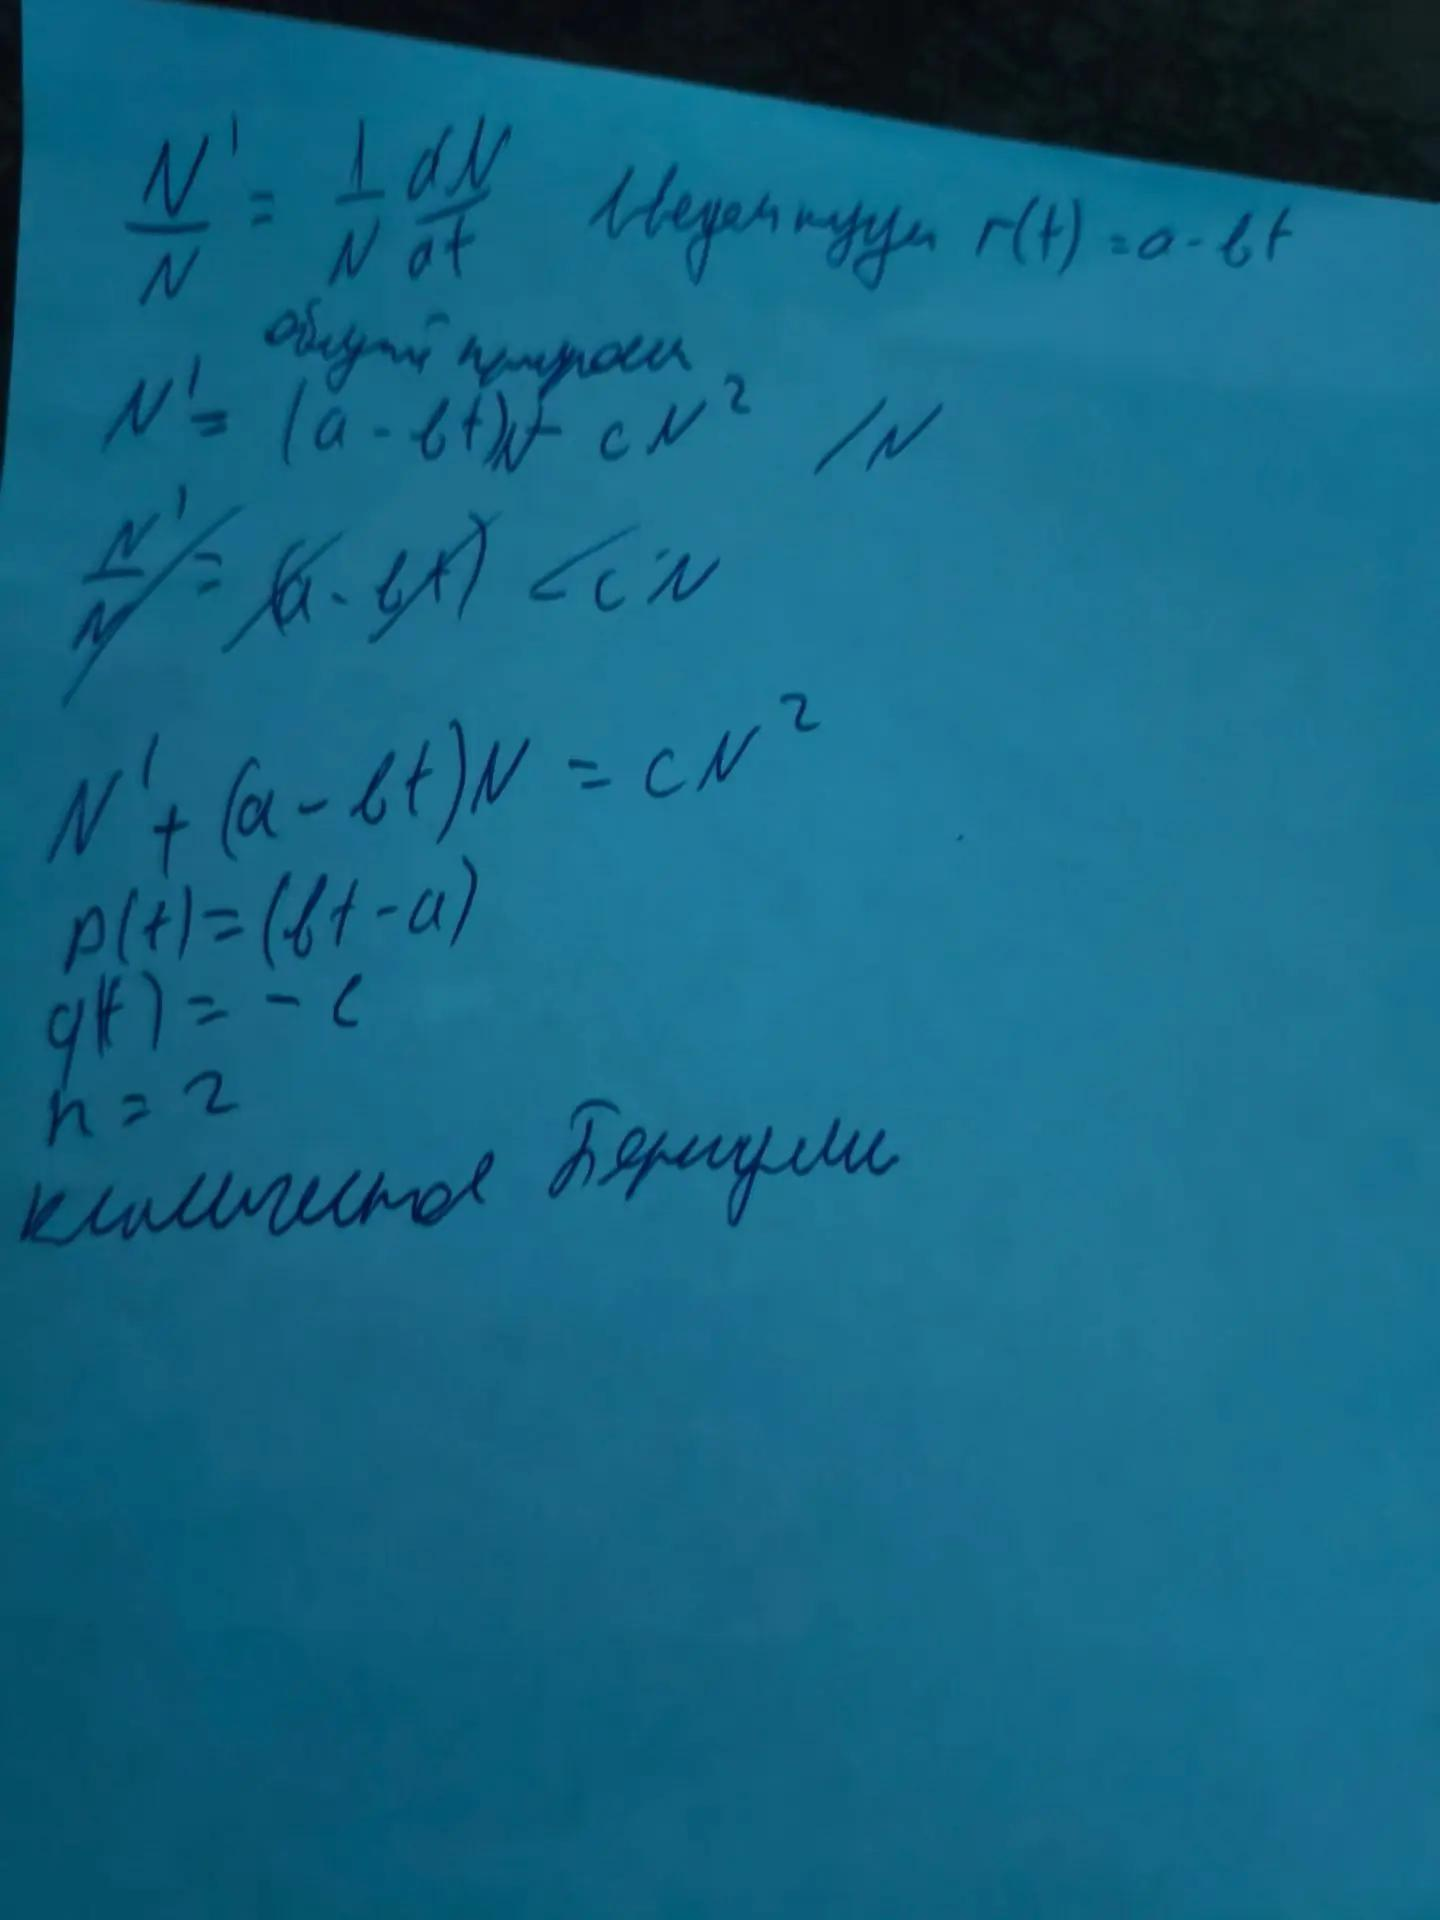

exp(1.0*t)/(3.33066907387547e-18*exp(1.0*t) + 2119761.47330607*sqrt(pi)*exp(0.015*t**2)*erf(0.122474487139159*t - 4.08248290463863) + 3757189.35719163*exp(0.015*t**2))


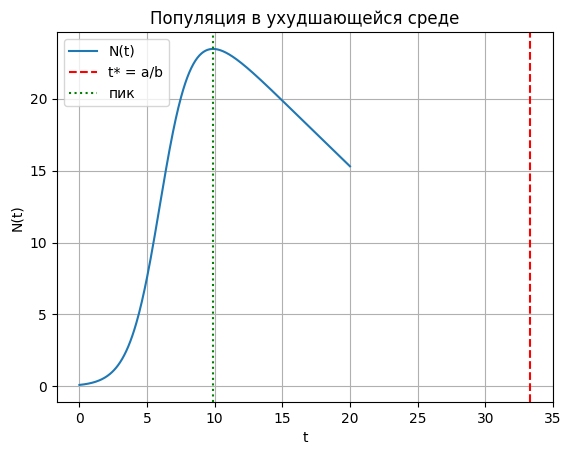

In [22]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

t = sp.symbols('t', positive=True)
N = sp.Function('N')

# сразу в числах
a_val, b_val, c_val, N0_val = 1.0, 0.03, 0.03, 0.1

# канонический вид Бернулли
p = b_val * t - a_val
q = -c_val
n = 2

ode = sp.Eq(N(t).diff(t) + p * N(t), q * N(t)**n)
sol = sp.dsolve(ode, N(t), ics={N(0): N0_val})
sol = sp.simplify(sol.rhs)
print(sol)

# график
# вот тут чутка нейронка подсказала без modules='sympy' не работало я разобрался почему так
f = sp.lambdify(t, sol, modules='sympy')
t_vals = np.linspace(0, 20, 400)
N_vals = np.array([float(f(ti)) for ti in t_vals])

t_star = a_val / b_val
t_peak = t_vals[np.argmax(N_vals)]

plt.plot(t_vals, N_vals, label='N(t)')
plt.axvline(t_star, color='r', ls='--', label='t* = a/b')
plt.axvline(t_peak, color='g', ls=':', label='пик')
plt.xlabel('t'); plt.ylabel('N(t)'); plt.grid(True)
plt.title('Популяция в ухудшающейся среде')
plt.legend()
plt.show()